# ERA5-Land daily air temperature and soil water EDA

Explore **validated development dates** from the shared study configuration. The expanded profile exposes 2020–2024 training; held-out 2025 test values are excluded from descriptive summaries. Actual coverage, missing intervals, and partial-period denominators are printed below.

| Predictor | Earth Engine band | Interpretation | Stored unit |
|---|---|---|---|
| Air temperature | `temperature_2m` | Mean of hourly 2 m temperatures for each UTC day | K |
| Soil water | `volumetric_soil_water_layer_1` | Mean of modeled water in the 0–7 cm layer for each UTC day | m³/m³ |

[Official Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_DAILY_AGGR) · [Refresh instructions](../docs/era5-land-refresh.md)

Install the project with `.venv/bin/python -m pip install -e . --no-deps` before running from either the repository root or `EDA/`. Source files retain the native 0.1° grid without peatland clipping or 5 km resampling. These are delayed retrospective UTC reanalysis aggregates, not WITA observations or immediately available operational forecasts. Modeled soil water is not a direct peat-moisture or water-table observation. The paper leaves exact bands, layer, aggregation and timezone unspecified; the choices above are local reconstruction decisions.


In [1]:
import os
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import shape
from shapely.plotting import plot_polygon

from peatguard import find_root, load_study
from peatguard.era5_land import load_development, summarize_development

ROOT = find_root()
# Set an explicit as_of timestamp/date when reproducing a dated run.
study = load_study(root=ROOT, profile="expanded", end=os.getenv("PEATGUARD_END", "latest"), as_of=os.getenv("PEATGUARD_AS_OF"))


## Available source files: training and 2025 test

The table includes test-year file availability. The plots below still use training dates only. File presence and recorded source coverage do not establish complete model-label coverage.

In [2]:
source_manifest = json.loads((ROOT / study.config["sources"]["era5_land"]["directory"] / "manifest.json").read_text())
source_availability = pd.DataFrame([
    {"year": item["year"], "role": role,
     "file_present": (ROOT / item["file"]).is_file(),
     "recorded_days": item.get("days", "annual map"), "file": item["file"]}
    for item in source_manifest["years"]
    for role, (start, end) in study.profile_config["splits"].items()
    if int(start[:4]) <= int(item["year"]) <= int(end[:4])
]).sort_values(["year", "role"]).reset_index(drop=True)
print("2025 is registered as TEST data; training summaries below stop at 2024.")
display(source_availability)


2025 is registered as TEST data; training summaries below stop at 2024.


,year,role,file_present,recorded_days,file
0,2020,train,True,366,data/interim/era5_land_daily/era5_land_kaliman...
1,2021,train,True,365,data/interim/era5_land_daily/era5_land_kaliman...
2,2022,train,True,365,data/interim/era5_land_daily/era5_land_kaliman...
3,2023,train,True,365,data/interim/era5_land_daily/era5_land_kaliman...
4,2024,train,True,366,data/interim/era5_land_daily/era5_land_kaliman...
5,2025,test,True,365,data/interim/era5_land_daily/.partitions/era5_...


## 1. Load validated data and report actual coverage

The loader validates source checksums, dates, grids, band ranges and missingness before exposing development values. It imports legacy annual files and cumulative partial partitions through the active manifest. Kelvin-to-Celsius conversion is only for presentation. Missing source dates remain gaps, and the report states which requested development dates are absent.


In [3]:
loaded = load_development(study)
latitude, longitude = loaded["latitude"], loaded["longitude"]
dates = pd.DatetimeIndex(loaded["dates"])
print("Source:", loaded["manifest"]["earth_engine_collection"])
print("Grid:", len(latitude), "rows ×", len(longitude), "columns")
print(loaded["caption"])
print("Missing development intervals:", loaded["missing_development_ranges"])
print("This province-level EDA does not establish peat-cell feature eligibility.")


Source: ECMWF/ERA5_LAND/DAILY_AGGR
Grid: 96 rows × 111 columns
2020-01-01–2024-12-31 UTC; 1827/1827 requested development days; partial periods use observed valid-day denominators
Missing development intervals: []
This province-level EDA does not establish peat-cell feature eligibility.


In [4]:
expected = pd.DatetimeIndex(study.development_dates())
print(f"Development days present: {len(dates):,} / {len(expected):,}")
print("Missing dates:", len(expected.difference(dates)))
assert dates.is_unique and dates.is_monotonic_increasing
assert dates.isin(expected).all(), "Held-out or outside-study dates reached development EDA"


Development days present: 1,827 / 1,827
Missing dates: 0


## 2. Mask to the five provinces for descriptive summaries

The downloaded rectangle includes ocean and neighboring countries. This mask selects native pixels whose centers lie in BIG's five Kalimantan province polygons. It is **not** the final peatland mask.

In [5]:
with (ROOT / "data/raw/boundaries/big_kalimantan_provinces.geojson").open(encoding="utf-8") as file:
    province_geojson = json.load(file)

def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]

provinces = [(feature["properties"]["WADMPR"], shape({
    "type": feature["geometry"]["type"],
    "coordinates": keep_xy(feature["geometry"]["coordinates"]),
})) for feature in province_geojson["features"]]
province_union = shapely.union_all([geometry for _, geometry in provinces])
lon_grid, lat_grid = np.meshgrid(longitude, latitude)
province_mask = shapely.contains_xy(province_union, lon_grid, lat_grid)
print(f"Native pixel centers inside five provinces: {province_mask.sum():,}")

Native pixel centers inside five provinces: 4,343


## 3. Quality, units and valid-day denominators

Temperature is converted to Celsius (`K − 273.15`) for display. Layer-1 soil water remains a volume fraction: 0.4 means 40% of modeled soil volume. Tables show the observed/valid days and calendar-day denominators; incomplete years are marked explicitly. Missing source days are not zero-valued observations. Coastal source masks remain missing, and unexpected changes in the source mask block loading.


In [6]:
daily, monthly, quality, mean_maps, map_valid_days = summarize_development(loaded, province_mask)
print("Period:", loaded["caption"])
quality


Period: 2020-01-01–2024-12-31 UTC; 1827/1827 requested development days; partial periods use observed valid-day denominators


,observed_days,calendar_days,complete_year,temperature_C_valid_days,temperature_C_min,temperature_C_max,soil_water_fraction_valid_days,soil_water_fraction_min,soil_water_fraction_max
year,,,,,,,,,
2020,366,366,True,366,23.660377,26.978141,366,0.357835,0.425664
2021,365,365,True,365,23.165525,27.050791,365,0.343746,0.424422
2022,365,365,True,365,23.072487,26.502455,365,0.341878,0.424500
2023,365,365,True,365,23.689024,27.450628,365,0.295166,0.424752
2024,366,366,True,366,23.894759,27.319666,366,0.309927,0.422764


## 4. Daily and monthly patterns

Spatial means describe the five provinces, not individual peatland cells. The daily axis is reindexed to show breaks for absent days. Monthly means use only valid days and expose each variable's count and `complete_month` flag; a partial month is not a full-month climate estimate. No full-year climatology is inferred from incomplete years.


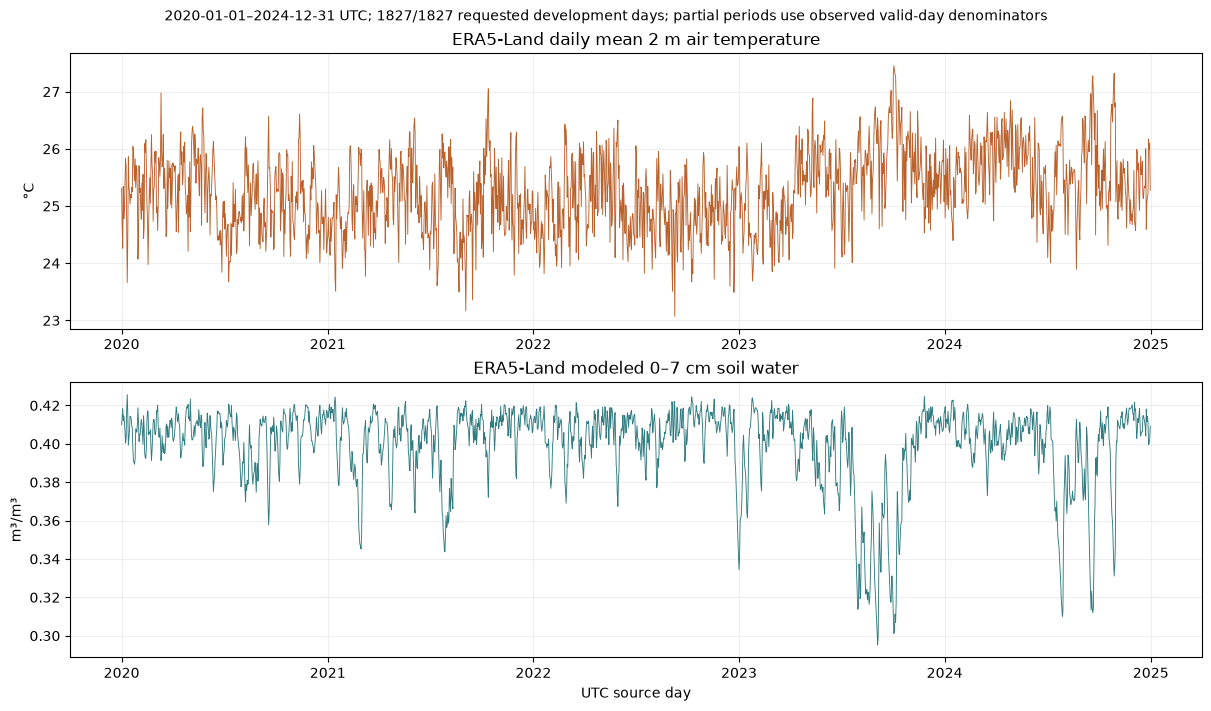

In [7]:
plot_daily = daily.reindex(pd.date_range(dates.min(), dates.max(), freq="D"))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(plot_daily.index, plot_daily.temperature_C, color="#bb622c", linewidth=0.65)
axes[0].set(title="ERA5-Land daily mean 2 m air temperature", ylabel="°C")
axes[1].plot(plot_daily.index, plot_daily.soil_water_fraction, color="#307c80", linewidth=0.65)
axes[1].set(title="ERA5-Land modeled 0–7 cm soil water", ylabel="m³/m³", xlabel="UTC source day")
fig.suptitle(loaded["caption"], fontsize=10)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()


In [8]:
# Partial months retain their actual valid-day counts and completion flags.
monthly.round(3)


temperature_C       soil_water_fraction       calendar_days  \
                    mean count                mean count                 
date                                                                     
2020-01-01        25.185    31               0.408    31            31   
2020-02-01        25.291    29               0.405    29            29   
2020-03-01        25.466    31               0.406    31            31   
2020-04-01        25.393    30               0.409    30            30   
2020-05-01        25.780    31               0.407    31            31   
2020-06-01        25.016    30               0.403    30            30   
2020-07-01        24.609    31               0.406    31            31   
2020-08-01        25.296    31               0.386    31            31   
2020-09-01        24.926    30               0.402    30            30   
2020-10-01        25.227    31               0.406    31            31   
2020-11-01        25.023    30               0.410    30            30   
2020-12-01        24.991    31               0.409    31            31   
2021-01-01        24.637    31               0.408    31            31   
2021-02-01        25.147    28               0.388    28            28   
2021-03-01        24.911    31               0.404    31            31   
2021-04-01        25.373    30               0.395    30            30   
2021-05-01        25.405    31               0.406    31            31   
2021-06-01        25.077    30               0.399    30            30   
2021-07-01        25.097    31               0.386    31            31   
2021-08-01        24.827    31               0.396    31            31   
2021-09-01        24.798    30               0.410    30            30   
2021-10-01        25.473    31               0.405    31            31   
2021-11-01        25.008    30               0.413    30            30   
2021-12-01        24.985    31               0.410    31            31   
2022-01-01        24.735    31               0.407    31            31   
2022-02-01        24.937    28               0.402    28            28   
2022-03-01        25.272    31               0.402    31            31   
2022-04-01        25.270    30               0.405    30            30   
2022-05-01        25.483    31               0.407    31            31   
2022-06-01        24.721    30               0.409    30            30   
2022-07-01        24.962    31               0.402    31            31   
2022-08-01        24.868    31               0.403    31            31   
2022-09-01        24.811    30               0.409    30            30   
2022-10-01        24.767    31               0.413    31            31   
2022-11-01        24.934    30               0.413    30            30   
2022-12-01        24.839    31               0.402    31            31   
2023-01-01        24.796    31               0.392    31            31   
2023-02-01        24.942    28               0.404    28            28   
2023-03-01        24.667    31               0.414    31            31   
2023-04-01        25.427    30               0.401    30            30   
2023-05-01        25.837    31               0.394    31            31   
2023-06-01        25.467    30               0.390    30            30   
2023-07-01        25.153    31               0.387    31            31   
2023-08-01        25.834    31               0.337    31            31   
2023-09-01        26.019    30               0.344    30            30   
2023-10-01        26.274    31               0.360    31            31   
2023-11-01        25.637    30               0.405    30            30   
2023-12-01        25.417    31               0.412    31            31   
2024-01-01        25.406    31               0.410    31            31   
2024-02-01        25.648    29               0.405    29            29   
2024-03-01        25.806    31               0.403    31            31   
2024-04-01     

## 5. Spatial patterns over observed development days

Maps divide each pixel's sum by its own finite-day count across the loaded dates, rather than equally weighting unequal annual partitions. Missing pixels remain missing. Coverage is reported in the caption and map-valid-day counts below. A 5 km analysis grid is finer than the source pixels; interpolation cannot add local climate detail.


Pixel valid-day range per band: [(0, 1827), (0, 1827)]


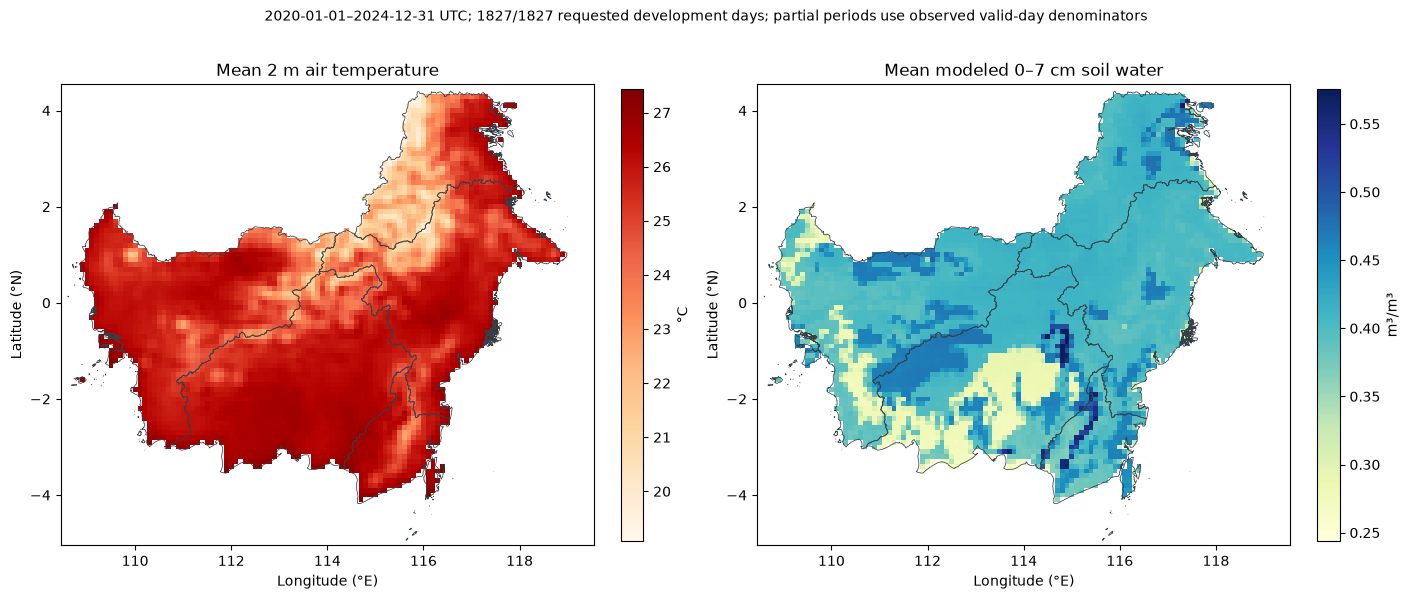

In [9]:
mean_temperature_C, mean_soil_water = mean_maps
print("Pixel valid-day range per band:", [(int(v.min()), int(v.max())) for v in map_valid_days[:, province_mask]])
step_lon = np.diff(longitude).mean()
step_lat = abs(np.diff(latitude).mean())
extent = [longitude.min()-step_lon/2, longitude.max()+step_lon/2,
          latitude.min()-step_lat/2, latitude.max()+step_lat/2]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, values, cmap, title, label in [
    (axes[0], mean_temperature_C, "OrRd", "Mean 2 m air temperature", "°C"),
    (axes[1], mean_soil_water, "YlGnBu", "Mean modeled 0–7 cm soil water", "m³/m³"),
]:
    image = np.ma.masked_where(~province_mask, values)
    im = ax.imshow(image, origin="upper", extent=extent, cmap=cmap, interpolation="nearest")
    for _, geom in provinces:
        plot_polygon(geom.simplify(0.003, preserve_topology=True), ax=ax,
                     add_points=False, facecolor="none", edgecolor="#354049", linewidth=0.55)
    ax.set(title=title, xlabel="Longitude (°E)", ylabel="Latitude (°N)")
    ax.set_aspect("equal", adjustable="box")
    fig.colorbar(im, ax=ax, shrink=0.8, label=label)
fig.suptitle(loaded["caption"], fontsize=10)
plt.show()

## Interpretation before preprocessing

- Daily means retain the source **UTC** boundary. WITA aggregates require recomputing from hourly data.
- The paper does not fix exact bands or depth; 2 m temperature and modeled 0–7 cm soil water are declared reconstruction assumptions.
- Current provider asset dates and retrieval timestamps do not establish availability at a historical forecast issue time. A lag/forecast-source policy is still required for prospective predictions.
- Coverage reports do not silently fill source gaps. Missing or partial development periods remain visible, and held-out data are excluded from ordinary plots.
- Province descriptive summaries do not define peatland-cell modeling coverage. Later source-to-cell mapping must validate incoming missingness and preserve source semantics.
